In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,LSTM,Dropout
from tensorflow.keras.callbacks import ModelCheckpoint,EarlyStopping

import warnings
warnings.filterwarnings('ignore')

import os 
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
tf.compat.v1.logging.set_verbosity(tf.compat.v1.logging.ERROR)

In [5]:
df = pd.read_csv("TSLA.csv")

In [6]:
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-29,19.000000,25.00,17.540001,23.889999,23.889999,18766300
1,2010-06-30,25.790001,30.42,23.299999,23.830000,23.830000,17187100
2,2010-07-01,25.000000,25.92,20.270000,21.959999,21.959999,8218800
3,2010-07-02,23.000000,23.10,18.709999,19.200001,19.200001,5139800
4,2010-07-06,20.000000,20.00,15.830000,16.110001,16.110001,6866900


In [7]:
df.shape

(2416, 7)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2416 entries, 0 to 2415
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2416 non-null   str    
 1   Open       2416 non-null   float64
 2   High       2416 non-null   float64
 3   Low        2416 non-null   float64
 4   Close      2416 non-null   float64
 5   Adj Close  2416 non-null   float64
 6   Volume     2416 non-null   int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 132.3 KB


In [9]:
df.describe()

,Open,High,Low,Close,Adj Close,Volume
count,2416.000000,2416.000000,2416.000000,2416.000000,2416.000000,2.416000e+03
mean,186.271147,189.578224,182.916639,186.403651,186.403651,5.572722e+06
std,118.740163,120.892329,116.857591,119.136020,119.136020,4.987809e+06
min,16.139999,16.629999,14.980000,15.800000,15.800000,1.185000e+05
25%,34.342498,34.897501,33.587501,34.400002,34.400002,1.899275e+06
50%,213.035004,216.745002,208.870002,212.960007,212.960007,4.578400e+06
75%,266.450012,270.927513,262.102501,266.774994,266.774994,7.361150e+06
max,673.690002,786.140015,673.520020,780.000000,780.000000,4.706500e+07


In [10]:
df["Date"] = pd.to_datetime(df["Date"])

In [11]:
tesla_df = df[["Date","Close"]]

In [12]:
tesla_df.head()

,Date,Close
0,2010-06-29,23.889999
1,2010-06-30,23.830000
2,2010-07-01,21.959999
3,2010-07-02,19.200001
4,2010-07-06,16.110001


In [13]:
tesla_df["Date"].min()

Timestamp('2010-06-29 00:00:00')

In [14]:
tesla_df["Date"].max()

Timestamp('2020-02-03 00:00:00')

In [15]:
tesla_df.index = tesla_df["Date"]

In [16]:
tesla_df

,Date,Close
Date,,
2010-06-29,2010-06-29,23.889999
2010-06-30,2010-06-30,23.830000
2010-07-01,2010-07-01,21.959999
2010-07-02,2010-07-02,19.200001
2010-07-06,2010-07-06,16.110001
...,...,...
2020-01-28,2020-01-28,566.900024
2020-01-29,2020-01-29,580.989990
2020-01-30,2020-01-30,640.809998


In [17]:
tesla_df.drop("Date",axis=1,inplace=True)

In [18]:
result_df = tesla_df.copy()

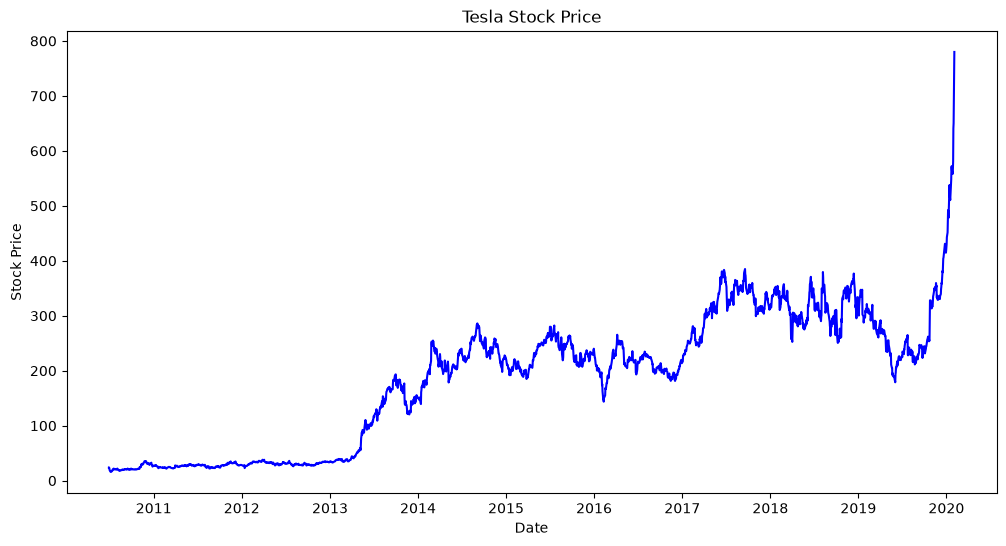

In [19]:
plt.figure(figsize=(12,6))
plt.plot(tesla_df['Close'],color='blue')
plt.ylabel('Stock Price')
plt.title('Tesla Stock Price')
plt.xlabel("Date")
plt.show()

In [21]:
tesla_df = tesla_df.values

In [22]:
tesla_df = tesla_df.astype('float32')

In [23]:
def split_data(df,test_size):
    pos = int(round(len(df) * (1-test_size)))
    train = df[:pos]
    test = df[pos:]
    return train,test,pos

In [24]:
train ,test,pos = split_data(tesla_df,0.2)

In [25]:
train.shape

(1933, 1)

In [26]:
test.shape

(483, 1)

In [27]:
def create_features(data,lookback):
    X,y = [],[]
    for i in range(lookback,len(data)):
        X.append(data[i-lookback:i,0])
        y.append(data[i,0])
    return np.array(X),np.array(y)

In [28]:
lookback = 20

In [29]:
X_train,y_train = create_features(train,lookback)

In [30]:
X_test,y_test = create_features(test,lookback)

In [32]:
X_train = np.reshape(X_train,(X_train.shape[0], 1, X_train.shape[1]))
X_test = np.reshape(X_test,(X_test.shape[0], 1, X_test.shape[1]))

In [33]:
y_train = y_train.reshape(-1,1)
y_test = y_test.reshape(-1,1)

In [34]:
model = Sequential()

model.add(LSTM(
    units=50,
    activation='relu',
    input_shape=(X_train.shape[1],lookback)
))

model.add(Dropout(0.2))
model.add(Dense(1))

In [35]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 50)                  │          14,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,251 (55.67 KB)

 Trainable params: 14,251 (55.67 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
model.compile(loss="mean_squared_error",optimizer='adam')

In [37]:
callbacks = [EarlyStopping(monitor='val_loss',patience=3,verbose=1,mode='min'),
            ModelCheckpoint(monitor='val_los',filepath='mymodel.keras',mode='min',save_best_only=True,save_weights_only=False,verbose=1)]

In [39]:
history = model.fit(x=X_train,
                    y=y_train,
                    epochs=100,
                    batch_size=20,
                    validation_data=(X_test,y_test),
                    callbacks=callbacks,
                    shuffle=False)

Epoch 1/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2078.0239
Epoch 1: finished saving model to mymodel.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 2078.0239 - val_loss: 3274.6475
Epoch 2/100
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1394.4102
Epoch 2: finished saving model to mymodel.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 1406.6283 - val_loss: 1274.3538
Epoch 3/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1515.1442
Epoch 3: finished saving model to mymodel.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1515.1442 - val_loss: 1425.5958
Epoch 4/100
89/96 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1193.3441
Epoch 4: finished saving model to mymodel.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 1474.6456 - val_loss: 908.2256
Epoch 5/100
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1433.5179
Epoch 5: finished saving model to mymodel.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 1453.5992 - val_loss: 1090.2874
Epoch 6/100
95/9

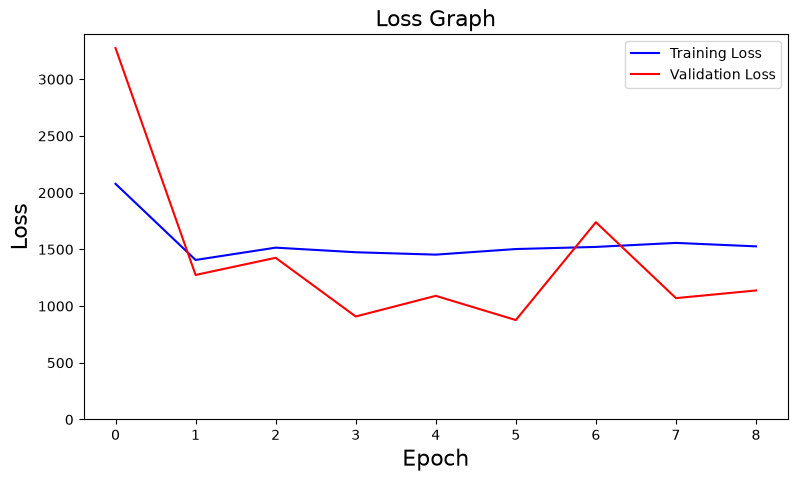

In [40]:
plt.figure(figsize=(20,5))
plt.subplot(1,2,2)
plt.plot(history.history['loss'], color='b', label='Training Loss')
plt.plot(history.history['val_loss'], color='r', label='Validation Loss')
plt.legend(loc="upper right")
plt.xlabel('Epoch', fontsize=16)
plt.ylabel('Loss', fontsize=16)
plt.ylim([0,max(plt.ylim())])
plt.title("Loss Graph", fontsize=16)

plt.show()

In [42]:
loss = model.evaluate(X_test,y_test,batch_size=20)

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1137.7673


In [43]:
loss * 100

113776.7333984375

In [44]:
train_predict = model.predict(X_train)
test_predict = model.predict(X_test)

60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
